In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_csv(
    PROJECT_ROOT / "data/results/focal_self_assertion_values.csv"
)

# The 20 Schwartz value columns
value_cols = df.columns[7:].tolist()

assert len(value_cols) == 20

print("Sentences:", len(df))
print("Countries:", df["iso3"].nunique())
print("Values:", len(value_cols))

Sentences: 1230
Countries: 18
Values: 20


In [2]:
# Step 1: Mean value scores for each country-year
annual_profiles = (
    df.groupby(["iso3", "year"])[value_cols]
    .mean()
)

# Step 2: Average annual profiles within each country
country_profiles = (
    annual_profiles.groupby("iso3")
    .mean()
)

print("Country-value matrix:", country_profiles.shape)

display(country_profiles.round(3))

Country-value matrix: (18, 20)


,Self-direction: thought,Self-direction: action,Stimulation,Hedonism,Achievement,Power: dominance,Power: resources,Face,Security: personal,Security: societal,Tradition,Conformity: rules,Conformity: interpersonal,Humility,Benevolence: caring,Benevolence: dependability,Universalism: concern,Universalism: nature,Universalism: tolerance,Universalism: objectivity
iso3,,,,,,,,,,,,,,,,,,,,
CHL,0.167,0.214,0.046,0.013,0.326,0.322,0.047,0.131,0.219,0.422,0.084,0.240,0.010,0.024,0.185,0.199,0.567,0.126,0.219,0.200
CHN,0.116,0.130,0.061,0.007,0.387,0.291,0.064,0.133,0.298,0.497,0.075,0.188,0.019,0.027,0.195,0.196,0.662,0.166,0.327,0.141
COL,0.076,0.129,0.051,0.018,0.233,0.248,0.061,0.120,0.312,0.501,0.041,0.181,0.010,0.027,0.232,0.170,0.649,0.185,0.205,0.147
GBR,0.189,0.171,0.059,0.005,0.463,0.285,0.057,0.093,0.225,0.471,0.092,0.180,0.011,0.027,0.225,0.242,0.415,0.134,0.164,0.224
GHA,0.092,0.169,0.034,0.006,0.324,0.342,0.214,0.198,0.158,0.314,0.121,0.217,0.012,0.040,0.170,0.188,0.513,0.065,0.175,0.192
IDN,0.071,0.199,0.033,0.004,0.295,0.416,0.007,0.222,0.114,0.480,0.066,0.228,0.012,0.018,0.140,0.187,0.697,0.041,0.226,0.118
IND,0.091,0.095,0.026,0.008,0.213,0.302,0.009,0.091,0.165,0.397,0.075,0.270,0.026,0.035,0.220,0.186,0.387,0.213,0.135,0.198
JOR,0.068,0.082,0.029,0.006,0.248,0.286,0.021,0.144,0.284,0.475,0.301,0.173,0.022,0.030,0.272,0.141,0.654,0.056,0.229,0.131
JPN,0.120,0.126,0.038,0.008,0.338,0.328,0.031,0.173,0.172,0.422,0.131,0.326,0.014,0.019,0.173,0.178,0.596,0.079,0.206,0.202


In [3]:
# Number of years contributing to each country's profile
years_per_country = (
    annual_profiles.reset_index()
    .groupby("iso3")["year"]
    .nunique()
)

print("Years represented per country:")
print(years_per_country)

assert len(country_profiles) == 18
assert country_profiles.notna().all().all()

output_path = (
    PROJECT_ROOT
    / "data/results/country_value_profiles.csv"
)

country_profiles.reset_index().to_csv(
    output_path, index=False
)

print("\nSaved:", output_path)

Years represented per country:
iso3
CHL    10
CHN    10
COL    10
GBR    10
GHA    10
IDN     9
IND     8
JOR    10
JPN    10
KAZ    10
KEN    10
PAK    10
POL    10
ROU    10
SAU    10
THA    10
TJK    10
USA    10
Name: year, dtype: int64

Saved: /Users/catherinexie/Documents/kgl-mockproject/data/results/country_value_profiles.csv


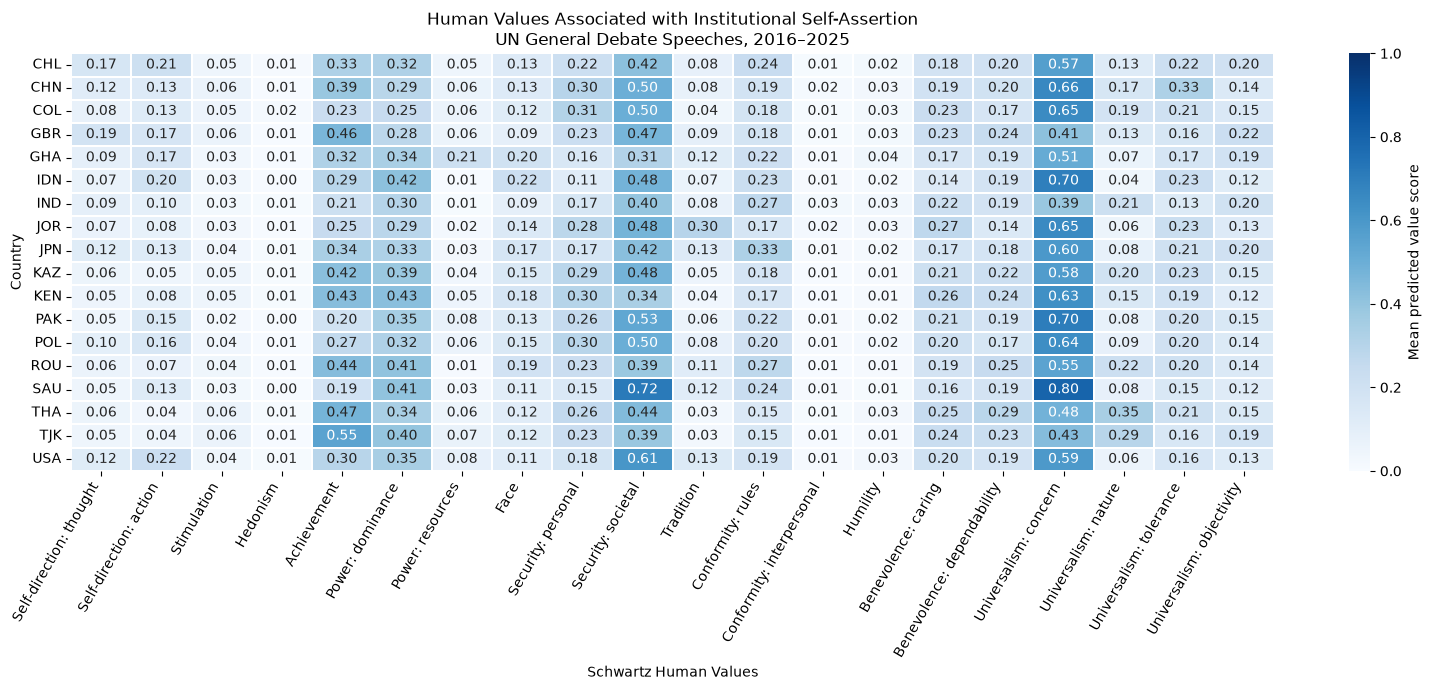

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 7))

sns.heatmap(
    country_profiles,
    cmap="Blues",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    cbar_kws={"label": "Mean predicted value score"}
)

plt.title(
    "Human Values Associated with Institutional Self-Assertion\n"
    "UN General Debate Speeches, 2016–2025"
)

plt.xlabel("Schwartz Human Values")
plt.ylabel("Country")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()